# Zaawansowana klasyczna segmentacja i ekstraktor cech morfometryczno-teksturowych dla skanów WSI


---

## 1. Weryfikacja połączenia ze skanami WSI na Dysku Google

In [1]:
from pathlib import Path
import openslide

drive = Path(r"G:\Mój Dysk\PKG-Post-NAT-BRCA")

if not drive.exists():
    raise FileNotFoundError(f"Nie znaleziono folderu Dysku Google: {drive}")

wsi_train = drive / "WSI_train"
svs_files = list(wsi_train.rglob("*.svs"))
print(f"Połączono z Dyskiem Google. Znaleziono łącznie {len(svs_files)} pełnych skanów WSI (.svs).")
if svs_files:
    sample_slide = openslide.OpenSlide(str(svs_files[0]))
    print(f"Przykładowy skan: {svs_files[0].name} | Wymiary bazowe (level 0): {sample_slide.dimensions} | MPP: {sample_slide.properties.get('openslide.mpp-x', 'N/A')}")
    sample_slide.close()

Połączono z Dyskiem Google. Znaleziono łącznie 69 pełnych skanów WSI (.svs).
Przykładowy skan: 99814.svs | Wymiary bazowe (level 0): (43823, 34049) | MPP: 0.50290000000000001


## 2. Przygotowanie zbiorów danych testowych (3 zbiory po min. 10 kafelków)
- **Zbiór Łatwy (Easy)**: Wysoki kontrast, ostre jądra, znormalizowane algorytmem Macenko.
- **Zbiór Średni (Medium)**: Surowe kafelki RAW o dużej zmienności odcieni barwienia H&E.
- **Zbiór Trudny (Hard)**: Kafelki z istotnymi artefaktami: nieostrość (blur), zagniecenia preparatu (folds), ślady markera lekarskiego.

In [2]:
from dataset_builder import generate_curated_datasets

# UWAGA: ponowne uruchomienie nadpisuje zawartość katalogu 'dataset/'
REBUILD_DATASET = False
if REBUILD_DATASET:
    generate_curated_datasets(drive_root=drive, output_dir=Path("dataset"), target_count=10)
else:
    for s in ["easy", "medium", "hard"]:
        print(s, len(list((Path("dataset") / s).glob("*.png"))), "kafelków")

easy 10 kafelków
medium 10 kafelków
hard 10 kafelków


### Wizualizacja przygotowanych zbiorów testowych (Easy, Medium, Hard)

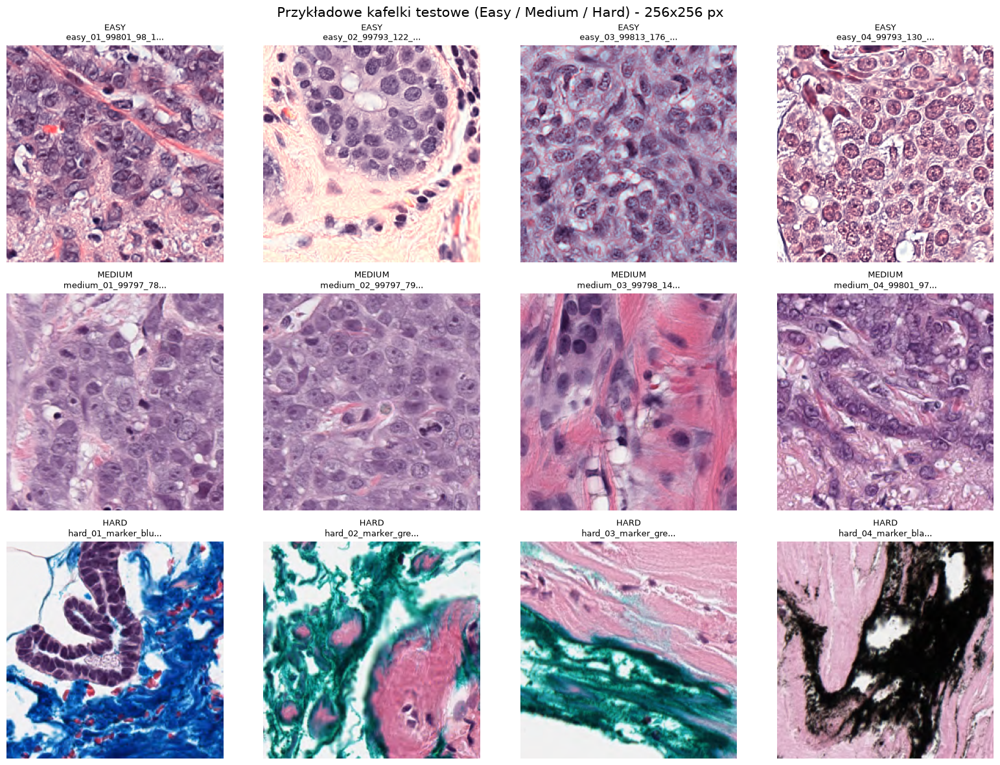

In [3]:
import cv2
import matplotlib.pyplot as plt
from pathlib import Path

def show_dataset_grid(dataset_dir="dataset", samples_per_set=4):
    categories = ["easy", "medium", "hard"]
    fig, axes = plt.subplots(len(categories), samples_per_set, figsize=(4 * samples_per_set, 12))
    
    for row_idx, cat in enumerate(categories):
        cat_path = Path(dataset_dir) / cat
        files = sorted(list(cat_path.glob("*.png")))[:samples_per_set]
        
        for col_idx, file_path in enumerate(files):
            img = cv2.imread(str(file_path))
            img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            ax = axes[row_idx, col_idx]
            ax.imshow(img_rgb)
            ax.set_title(f"{cat.upper()}\n{file_path.name[:18]}...", fontsize=9)
            ax.axis("off")
            
    plt.suptitle("Przykładowe kafelki testowe (Easy / Medium / Hard) - 256x256 px", fontsize=15, y=0.98)
    plt.tight_layout()
    plt.show()

show_dataset_grid()

## 3.1 Wstępna filtracja i dekonwolucja barwna (Color Deconvolution)

Obraz RGB **nie jest liniowy** względem ilości barwnika – zgodnie z prawem Lamberta-Beera natężenie światła maleje wykładniczo. Dlatego przechodzimy do **gęstości optycznej (OD)**, w której barwniki sumują się liniowo:

$$OD_c = -\log_{10}\left(\frac{I_c}{I_0}\right) = \sum_{s \in \{H,E,R\}} S_{s,c} \cdot C_s \quad\Rightarrow\quad C = OD \cdot S^{-1}$$

- $S$ – macierz barwników (wiersze: wektory OD Hematoksyliny, Eozyny i kanału rezydualnego),
- $C$ – stężenie barwnika w pikselu.

**Wstępna filtracja:** usunięcie kanału alfa, ograniczenie intensywności do $[1, 255]$ (ochrona przed $\log 0$ na czarnych markerach) oraz maska tkanki $OD > \beta = 0.15$.

Porównujemy dwie macierze barwników:
- **Ruifrok & Johnston (2001)** – stała, literaturowa,
- **Macenko (2009)** – estymowana z każdego kafelka (SVD w przestrzeni OD), adaptuje się do zmienności barwienia.

Implementacja: [`color_deconvolution.py`](color_deconvolution.py)

In [4]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from skimage.color import rgb2hed

from color_deconvolution import (color_deconvolution, rgb_to_od, od_to_rgb,
                                 stain_to_rgb, channel_to_uint8)

DATASET_DIR = Path("dataset")
SETS = ["easy", "medium", "hard"]

def load_rgb(path):
    return cv2.cvtColor(cv2.imread(str(path)), cv2.COLOR_BGR2RGB)

tiles = {s: sorted((DATASET_DIR / s).glob("*.png")) for s in SETS}
{s: len(v) for s, v in tiles.items()}

{'easy': 10, 'medium': 10, 'hard': 10}

### Walidacja implementacji
1. Odwracalność transformacji RGB → OD → RGB.
2. Zgodność kanału H (Ruifrok) z referencyjną implementacją `skimage.color.rgb2hed`.
3. Selektywność: średnie stężenie H na pikselach jąder vs. na pozostałej tkance.

In [5]:
import pandas as pd

rows = []
for s in SETS:
    for f in tiles[s]:
        img = load_rgb(f)
        rt_err = np.abs(od_to_rgb(rgb_to_od(img)).astype(int) - np.clip(img, 1, 255).astype(int)).max()
        res_r = color_deconvolution(img, "ruifrok")
        res_m = color_deconvolution(img, "macenko")
        sk_h = rgb2hed(img)[..., 0]
        rows.append({
            "zbiór": s,
            "plik": f.name[:30],
            "błąd RGB↔OD": rt_err,
            "corr(Ruifrok, skimage)": np.corrcoef(res_r.hematoxylin.ravel(), sk_h.ravel())[0, 1],
            "corr(Ruifrok, Macenko)": np.corrcoef(res_r.hematoxylin.ravel(), res_m.hematoxylin.ravel())[0, 1],
            "tkanka [%]": res_r.tissue_mask.mean() * 100,
        })

df_31 = pd.DataFrame(rows)
display(df_31.groupby("zbiór")[["błąd RGB↔OD", "corr(Ruifrok, skimage)", "corr(Ruifrok, Macenko)", "tkanka [%]"]]
        .mean().round(3))
df_31.round(3)

,błąd RGB↔OD,"corr(Ruifrok, skimage)","corr(Ruifrok, Macenko)",tkanka [%]
zbiór,,,,
easy,1.0,1.000,0.974,44.298
hard,1.0,0.958,0.980,64.725
medium,1.0,1.000,0.876,47.631


,zbiór,plik,błąd RGB↔OD,"corr(Ruifrok, skimage)","corr(Ruifrok, Macenko)",tkanka [%]
0,easy,easy_01_99801_98_113.png,1,1.000,0.981,52.391
1,easy,easy_02_99793_122_65.png,1,1.000,0.982,25.104
2,easy,easy_03_99813_176_58.png,1,1.000,0.930,64.127
3,easy,easy_04_99793_130_79.png,1,1.000,0.986,41.713
4,easy,easy_05_99797_71_74.png,1,1.000,0.983,47.119
5,easy,easy_06_99797_72_75.png,1,1.000,0.984,36.218
6,easy,easy_07_99797_73_76.png,1,1.000,0.977,35.202
7,easy,easy_08_99797_71_76.png,1,1.000,0.977,49.411
8,easy,easy_09_99797_83_76.png,1,1.000,0.982,44.666
9,easy,easy_10_99793_131_79.png,1,1.000,0.956,47.034


### Wizualizacja separacji barwników
Dla przykładowych kafelków z każdego zbioru: oryginał, mapa stężenia Hematoksyliny (jądra), mapa Eozyny (cytoplazma/podścielisko) oraz rekonstrukcje RGB pojedynczych barwników. Ostatnia kolumna to kanał H uzyskany macierzą Macenko.

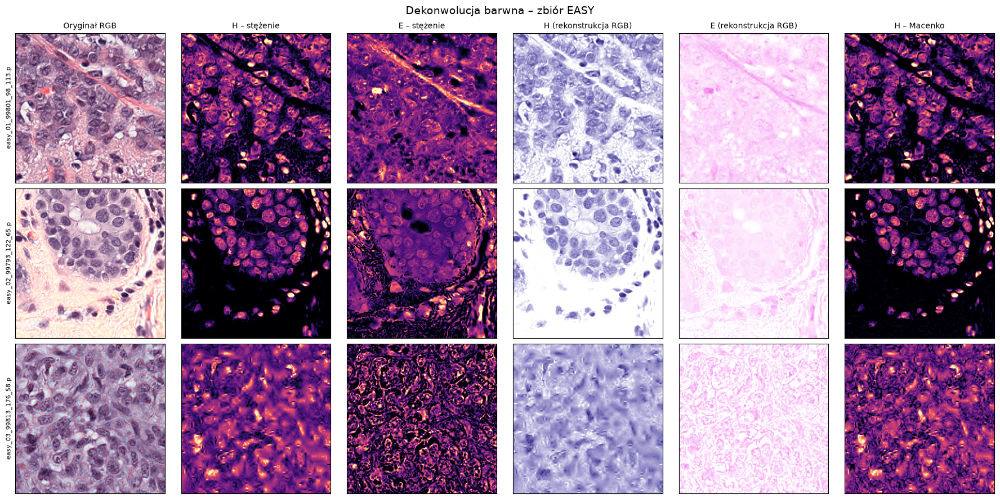

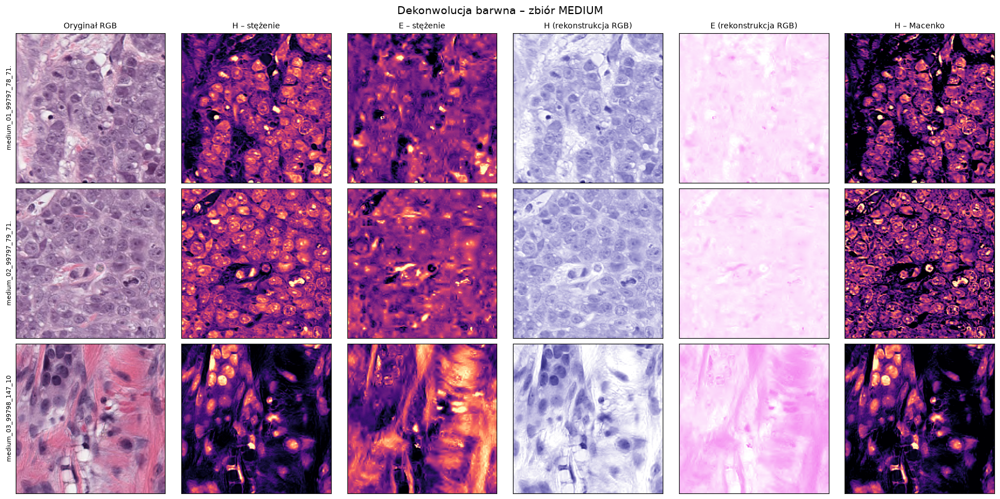

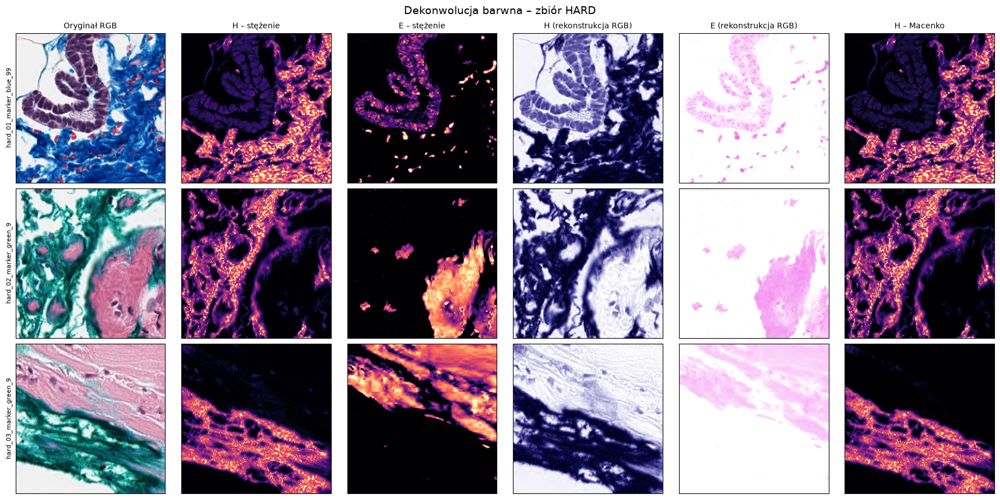

In [6]:
def show_deconvolution(paths, title):
    cols = ["Oryginał RGB", "H – stężenie", "E – stężenie", "H (rekonstrukcja RGB)",
            "E (rekonstrukcja RGB)", "H – Macenko"]
    fig, axes = plt.subplots(len(paths), len(cols), figsize=(3 * len(cols), 3 * len(paths)))
    axes = np.atleast_2d(axes)
    for i, p in enumerate(paths):
        img = load_rgb(p)
        r = color_deconvolution(img, "ruifrok")
        m = color_deconvolution(img, "macenko")
        panels = [img,
                  channel_to_uint8(r.hematoxylin), channel_to_uint8(r.eosin),
                  stain_to_rgb(r, 0), stain_to_rgb(r, 1),
                  channel_to_uint8(m.hematoxylin)]
        cmaps = [None, "magma", "magma", None, None, "magma"]
        for j, (panel, cm) in enumerate(zip(panels, cmaps)):
            ax = axes[i, j]
            ax.imshow(panel, cmap=cm)
            ax.set_xticks([]); ax.set_yticks([])
            if i == 0:
                ax.set_title(cols[j], fontsize=10)
        axes[i, 0].set_ylabel(p.name[:22], fontsize=8)
    fig.suptitle(title, fontsize=14)
    plt.tight_layout()
    plt.show()

for s in SETS:
    show_deconvolution(tiles[s][:3], f"Dekonwolucja barwna – zbiór {s.upper()}")

### Rozkład pikseli w przestrzeni OD
W przestrzeni OD piksele tkanki układają się wzdłuż dwóch kierunków odpowiadających wektorom barwników. Strzałki pokazują wektory H i E z macierzy Ruifroka (stałe) oraz Macenko (estymowane z danego kafelka). Na kafelkach z markerem lub silną zmiennością barwienia widać, że wektory literaturowe przestają pasować do danych.

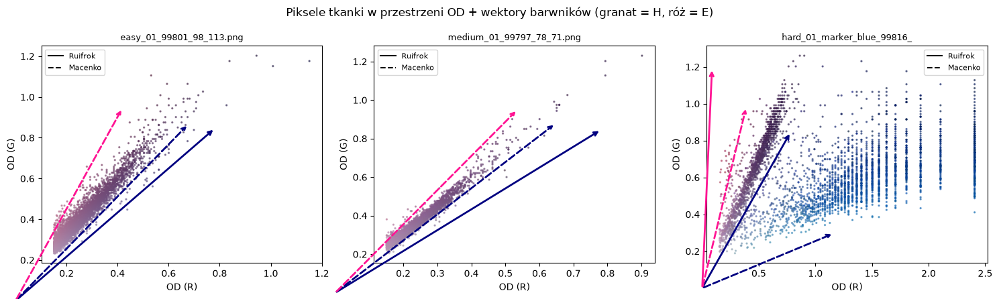

In [7]:
def plot_od_space(path, ax):
    img = load_rgb(path)
    r = color_deconvolution(img, "ruifrok")
    m = color_deconvolution(img, "macenko")
    od, colors = r.od[r.tissue_mask], img[r.tissue_mask] / 255.0
    if len(od) > 4000:
        idx = np.random.default_rng(0).choice(len(od), 4000, replace=False)
        od, colors = od[idx], colors[idx]
    ax.scatter(od[:, 0], od[:, 1], s=2, c=colors, alpha=0.5)
    for mat, ls, lab in [(r.stain_matrix, "-", "Ruifrok"), (m.stain_matrix, "--", "Macenko")]:
        for k, col in [(0, "navy"), (1, "deeppink")]:
            v = mat[k] * 1.2
            ax.annotate("", xy=(v[0], v[1]), xytext=(0, 0),
                        arrowprops=dict(arrowstyle="->", color=col, ls=ls, lw=2))
        ax.plot([], [], ls, color="k", label=lab)
    ax.set_xlabel("OD (R)"); ax.set_ylabel("OD (G)")
    ax.set_title(path.name[:26], fontsize=9)
    ax.legend(fontsize=8)

examples = [tiles["easy"][0], tiles["medium"][0], tiles["hard"][0]]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for p, ax in zip(examples, axes):
    plot_od_space(p, ax)
plt.suptitle("Piksele tkanki w przestrzeni OD + wektory barwników (granat = H, róż = E)")
plt.tight_layout(); plt.show()

### Zapis kanałów H i E dla kolejnych etapów
Mapy stężenia Hematoksyliny są wejściem do segmentacji jąder (Otsu + Watershed, etap 3.3). Zapisujemy je jako 8-bitowe PNG do `outputs/3_1_deconvolution/<zbiór>/`.

In [8]:
OUT_31 = Path("outputs") / "3_1_deconvolution"
for s in SETS:
    for method in ["ruifrok", "macenko"]:
        out_dir = OUT_31 / method / s
        out_dir.mkdir(parents=True, exist_ok=True)
        for f in tiles[s]:
            r = color_deconvolution(load_rgb(f), method)
            cv2.imwrite(str(out_dir / f"{f.stem}_H.png"), channel_to_uint8(r.hematoxylin))
            cv2.imwrite(str(out_dir / f"{f.stem}_E.png"), channel_to_uint8(r.eosin))
print("Zapisano do", OUT_31.resolve())

Zapisano do C:\Users\mateu\Desktop\WSI_segemntation_and_feature_extraction\outputs\3_1_deconvolution


## 3.2 Detekcja nieostrości i filtracja szumów (Blur Detection & Noise Filtering)

Zgodnie z **Sekcją 3 (Etap 2)** specyfikacji projektu etap ten realizuje dwa zadania:
1. **Detekcja nieostrości (Blur Detection):** wyznaczenie dyskretnego operatora Laplasjana $\nabla^2 I = \frac{\partial^2 I}{\partial x^2} + \frac{\partial^2 I}{\partial y^2}$ oraz jego wariancji $\text{Var}(\nabla^2 I)$ (globalnie na całym kafelku oraz lokalnie w ruchomym oknie $31\times 31\text{ px}$). Niska wariancja Laplasjana sygnalizuje utratę ostrości ogniskowania (*optical blur*) lub lokalne rozmycie na zagnieceniach preparatu (*tissue folds*).
2. **Filtracja szumów (Noise Filtering):** wygładzenie mapy stężenia Hematoksyliny nieliniowym **filtrem medianowym** (`cv2.medianBlur` o oknie $3\times 3$ oraz $5\times 5$), który tłumi wysokoczęstotliwościowy szum ziarnistości barwnika i artefakty kompresji JPEG przy zachowaniu ostrych granic jąder komórkowych przed progowaniem Otsu i transformacją Watershed w Etapie 3.3.

Implementacja: [`blur_and_denoise.py`](blur_and_denoise.py)

In [9]:
from blur_and_denoise import (
    analyze_and_filter, laplacian_variance, local_laplacian_variance_map,
    apply_median_filter, BLUR_THRESHOLD_GRAY, BLUR_THRESHOLD_H
)

rows_32 = []
for s in SETS:
    for f in tiles[s]:
        rgb = load_rgb(f)
        gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
        res_r = color_deconvolution(rgb, "ruifrok")
        h_u8 = channel_to_uint8(res_r.hematoxylin)

        lap_gray = laplacian_variance(gray)
        bf_3 = analyze_and_filter(h_u8, ksize=3, blur_threshold=BLUR_THRESHOLD_H)
        bf_5 = analyze_and_filter(h_u8, ksize=5, blur_threshold=BLUR_THRESHOLD_H)
        hf_red = (1.0 - bf_3.sharpness_after_median / max(bf_3.sharpness_var, 1e-6)) * 100.0

        rows_32.append({
            "zbiór": s,
            "plik": f.name[:32],
            "Var(∇²I) Gray": round(lap_gray, 1),
            "Var(∇²I) H_raw": round(bf_3.sharpness_var, 1),
            "Var(∇²I) H_med3": round(bf_3.sharpness_after_median, 1),
            "redukcja szumu HF [%]": round(hf_red, 1),
            "zachowanie krawędzi (k=3)": round(bf_3.edge_preservation_corr, 3),
            "zachowanie krawędzi (k=5)": round(bf_5.edge_preservation_corr, 3),
            "nieostrość (blur)": bf_3.is_blurry or (lap_gray < BLUR_THRESHOLD_GRAY),
        })

df_32 = pd.DataFrame(rows_32)
display(df_32.groupby("zbiór")[["Var(∇²I) Gray", "Var(∇²I) H_raw", "Var(∇²I) H_med3",
                               "redukcja szumu HF [%]", "zachowanie krawędzi (k=3)", "zachowanie krawędzi (k=5)"]].mean().round(2))
df_32

,Var(∇²I) Gray,Var(∇²I) H_raw,Var(∇²I) H_med3,redukcja szumu HF [%],zachowanie krawędzi (k=3),zachowanie krawędzi (k=5)
zbiór,,,,,,
easy,3531.79,5413.59,1923.87,61.03,0.91,0.72
hard,525.26,1014.84,382.48,47.57,0.95,0.84
medium,914.71,1672.66,747.43,53.08,0.94,0.80


,zbiór,plik,Var(∇²I) Gray,Var(∇²I) H_raw,Var(∇²I) H_med3,redukcja szumu HF [%],zachowanie krawędzi (k=3),zachowanie krawędzi (k=5),nieostrość (blur)
0,easy,easy_01_99801_98_113.png,1861.3,2226.8,1064.8,52.2,0.934,0.778,False
1,easy,easy_02_99793_122_65.png,1301.7,1269.3,643.6,49.3,0.968,0.902,False
2,easy,easy_03_99813_176_58.png,1066.9,1127.5,439.6,61.0,0.914,0.722,False
3,easy,easy_04_99793_130_79.png,6809.5,9807.7,3187.0,67.5,0.869,0.618,False
4,easy,easy_05_99797_71_74.png,5154.1,8549.4,3294.9,61.5,0.891,0.628,False
5,easy,easy_06_99797_72_75.png,5812.5,8411.8,2807.5,66.6,0.888,0.656,False
6,easy,easy_07_99797_73_76.png,3533.1,4362.1,1627.8,62.7,0.919,0.758,False
7,easy,easy_08_99797_71_76.png,3746.3,6818.3,2507.6,63.2,0.889,0.656,False
8,easy,easy_09_99797_83_76.png,5518.0,10659.4,3277.9,69.2,0.863,0.611,False
9,easy,easy_10_99793_131_79.png,514.5,903.6,388.0,57.1,0.943,0.825,False


### Wizualizacja detekcji nieostrości (Laplasjan) oraz filtracji medianowej ($3\times 3$ vs $5\times 5$)

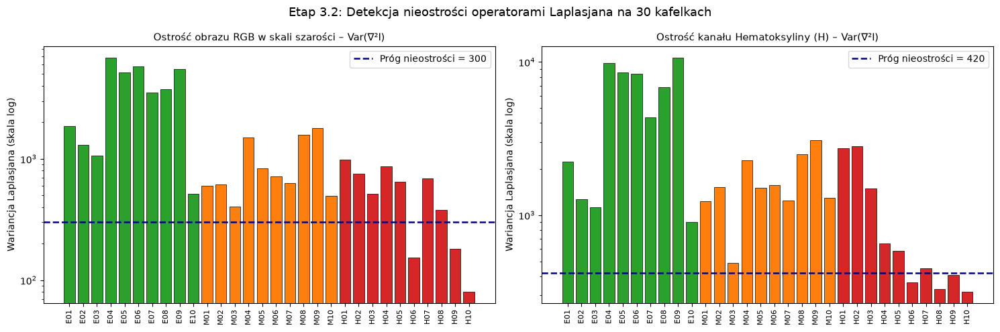

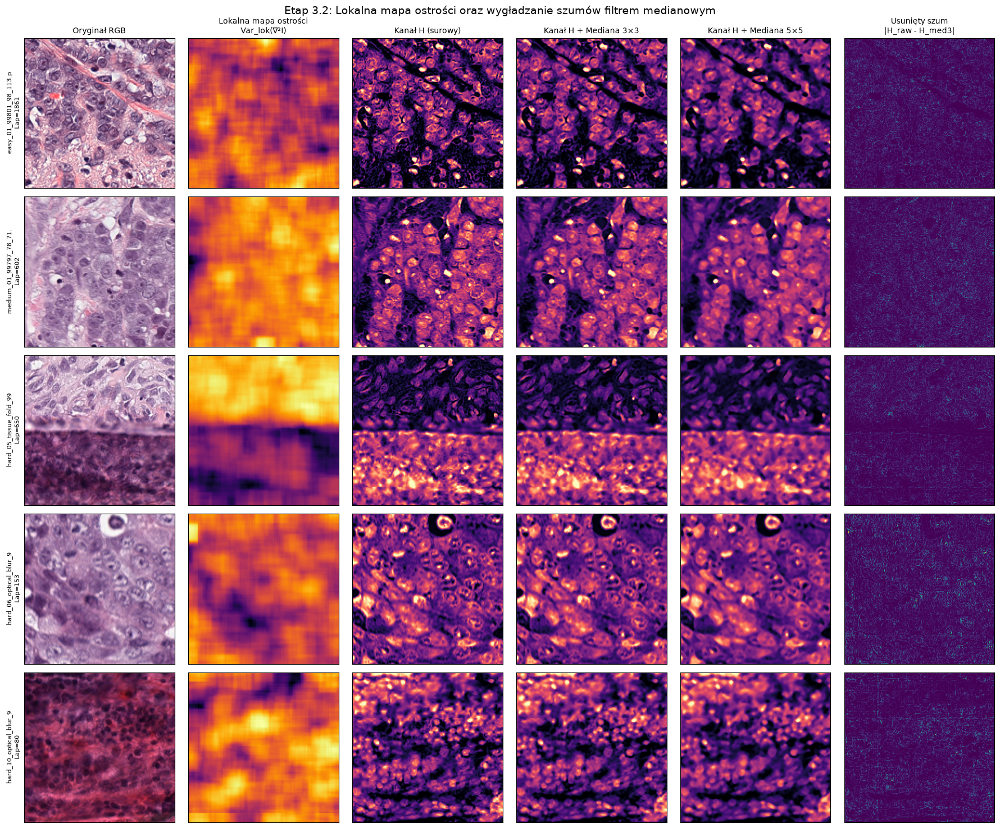

In [10]:
# 1. Wykres słupkowy wariancji Laplasjana dla wszystkich 30 kafelków
fig_bar, axes_b = plt.subplots(1, 2, figsize=(15, 5))
colors_map = {"easy": "#2ca02c", "medium": "#ff7f0e", "hard": "#d62728"}
for ax, col_name, thr, title in [
    (axes_b[0], "Var(∇²I) Gray", BLUR_THRESHOLD_GRAY, "Ostrość obrazu RGB w skali szarości – Var(∇²I)"),
    (axes_b[1], "Var(∇²I) H_raw", BLUR_THRESHOLD_H, "Ostrość kanału Hematoksyliny (H) – Var(∇²I)"),
]:
    x = np.arange(len(df_32))
    ax.bar(x, df_32[col_name], color=[colors_map[s] for s in df_32["zbiór"]], edgecolor="black", linewidth=0.5)
    ax.axhline(thr, color="navy", linestyle="--", linewidth=1.8, label=f"Próg nieostrości = {thr:.0f}")
    ax.set_yscale("log")
    ax.set_xticks(x)
    ax.set_xticklabels([f"{r['zbiór'][0].upper()}{i%10+1:02d}" for i, r in df_32.iterrows()], rotation=90, fontsize=8)
    ax.set_ylabel("Wariancja Laplasjana (skala log)")
    ax.set_title(title, fontsize=11)
    ax.legend()
plt.suptitle("Etap 3.2: Detekcja nieostrości operatorami Laplasjana na 30 kafelkach", fontsize=13)
plt.tight_layout(); plt.show()

# 2. Porównanie lokalnej mapy ostrości i filtru medianowego 3x3 vs 5x5
sample_paths = [tiles["easy"][0], tiles["medium"][0], tiles["hard"][4], tiles["hard"][5], tiles["hard"][9]]
cols_viz = ["Oryginał RGB", "Lokalna mapa ostrości\nVar_lok(∇²I)", "Kanał H (surowy)",
            "Kanał H + Mediana 3×3", "Kanał H + Mediana 5×5", "Usunięty szum\n|H_raw - H_med3|"]
fig_viz, axes_v = plt.subplots(len(sample_paths), len(cols_viz), figsize=(3 * len(cols_viz), 3 * len(sample_paths)))
for i, p in enumerate(sample_paths):
    rgb = load_rgb(p)
    gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
    h_u8 = channel_to_uint8(color_deconvolution(rgb, "ruifrok").hematoxylin)
    bf3 = analyze_and_filter(h_u8, ksize=3)
    bf5 = analyze_and_filter(h_u8, ksize=5)
    loc_map = local_laplacian_variance_map(gray, win_size=31)
    diff = cv2.absdiff(h_u8, bf3.filtered)
    for j, (pan, cm) in enumerate(zip([rgb, np.log1p(loc_map), h_u8, bf3.filtered, bf5.filtered, diff],
                                      [None, "inferno", "magma", "magma", "magma", "viridis"])):
        ax = axes_v[i, j]
        ax.imshow(pan, cmap=cm); ax.set_xticks([]); ax.set_yticks([])
        if i == 0: ax.set_title(cols_viz[j], fontsize=10)
    axes_v[i, 0].set_ylabel(f"{p.name[:22]}\nLap={laplacian_variance(gray):.0f}", fontsize=8)
plt.suptitle("Etap 3.2: Lokalna mapa ostrości oraz wygładzanie szumów filtrem medianowym", fontsize=14)
plt.tight_layout(); plt.show()

### Zapis odszumionych map Hematoksyliny i Eozyny dla Etapu 3.3 (Segmentacja Otsu + Watershed)

In [11]:
OUT_32 = Path("outputs") / "3_2_denoise"
for s in SETS:
    for method in ["ruifrok", "macenko"]:
        out_dir = OUT_32 / method / s
        out_dir.mkdir(parents=True, exist_ok=True)
        for f in tiles[s]:
            r = color_deconvolution(load_rgb(f), method)
            h_u8 = channel_to_uint8(r.hematoxylin)
            e_u8 = channel_to_uint8(r.eosin)
            cv2.imwrite(str(out_dir / f"{f.stem}_H_med3.png"), apply_median_filter(h_u8, 3))
            cv2.imwrite(str(out_dir / f"{f.stem}_H_med5.png"), apply_median_filter(h_u8, 5))
            cv2.imwrite(str(out_dir / f"{f.stem}_E_med3.png"), apply_median_filter(e_u8, 3))
print("Zapisano odszumione kanały do", OUT_32.resolve())

Zapisano odszumione kanały do C:\Users\mateu\Desktop\WSI_segemntation_and_feature_extraction\outputs\3_2_denoise


## 3.3 Segmentacja jąder komórkowych: Progowanie Otsu (globalne i adaptacyjne) + Watershed oraz weryfikacja z maską referencyjną

1. **Maskowanie artefaktów i normalizacja kanału $H$**: wykluczenie pikseli markerów chirurgicznych (niebieski, zielony, czarny tusz) przed wyznaczeniem percentyla 99.5% stężenia Hematoksyliny, aby silnie pochłaniający tusz nie zawyżał progu Otsu.
2. **Progowanie Otsu (`global` vs `adaptive`)**:
   - `global` – pojedynczy próg globalny $t_{\text{Otsu}}$ maksymalizujący wariancję międzyklasową $\sigma_B^2(t)=\omega_0(t)\omega_1(t)[\mu_0(t)-\mu_1(t)]^2$ na masce tkanki.
   - `adaptive` – przestrzennie adaptacyjna mapa progu $T(x,y) = \min(0.55\,t_{\text{Otsu}} + 0.45\,T_{\text{lok}}(x,y),\; 1.06\,t_{\text{Otsu}})$ z lokalnym oknem gaussowskim $75\times 75\text{ px}$ i ujemnym offsetem $-0.22\sigma$, co zapobiega sklejaniu zagnieceń tkanki (*tissue folds*) i jednocześnie **nie wygryza środków jąder**.
3. **Czyszczenie morfologiczne i Transformacja Wododziałowa (Watershed)**: otwarcie morfologiczne, wypełnienie dziur, transformata odległości Euklidesowej $D(x)$, ekstrakcja markerów $h$-maxima ($h = \text{DEFAULT\_H}$) i zalewanie basenów $-D(x)$ rozdzielające stykające się jądra.
4. **Weryfikacja z maską referencyjną i strojenie hiperparametrów (`MIN_NUCLEUS_AREA`, `MAX_NUCLEUS_AREA`, `DEFAULT_H`)**: ocena jakości za pomocą miar **Dice (F1)**, **IoU (Jaccard)**, **Precision**, **Recall** oraz obiektowego **Object-F1**.

Implementacja: [`nuclei_segmentation.py`](nuclei_segmentation.py)

In [ ]:
from nuclei_segmentation import (
    prepare_h_channel, segment_nuclei, build_reference_mask, evaluate_segmentation,
    overlay_contours, overlay_comparison, colorize_labels,
    MIN_NUCLEUS_AREA, MAX_NUCLEUS_AREA, DEFAULT_H
)

def segment_tile(path, method="ruifrok", mode="adaptive", use_watershed=True,
                 suppress_markers=True, min_area=MIN_NUCLEUS_AREA, max_area=MAX_NUCLEUS_AREA, h_val=DEFAULT_H):
    rgb = load_rgb(path)
    h_med, valid, marker = prepare_h_channel(rgb, method=method, median_ksize=3, suppress_markers=suppress_markers)
    seg = segment_nuclei(h_med, valid, mode=mode, h=h_val, use_watershed=use_watershed,
                         min_area=min_area, max_area=max_area)
    return rgb, h_med, valid, seg

# Ewaluacja global vs adaptive względem maski referencyjnej na wszystkich 30 kafelkach
rows_33 = []
ref_cache = {}
for s in SETS:
    for f in tiles[s]:
        rgb = load_rgb(f)
        ref = build_reference_mask(rgb)
        ref_cache[f] = ref
        for mode in ["global", "adaptive"]:
            _, h_med, valid, seg = segment_tile(f, "ruifrok", mode=mode)
            m = evaluate_segmentation(seg.labels, ref)
            rows_33.append({
                "zbiór": s, "kafelek": f.name[:24], "tryb Otsu": mode,
                "próg Otsu": round(seg.threshold, 1),
                "składowe spójne": seg.n_components,
                "jądra po Watershed (N)": seg.n_nuclei,
                "N referencyjne": m.n_ref,
                "Dice": round(m.dice, 3), "IoU": round(m.iou, 3),
                "Precision": round(m.precision, 3), "Recall": round(m.recall, 3),
                "Object-F1": round(m.object_f1, 3),
            })

df_33 = pd.DataFrame(rows_33)
display(df_33.groupby(["zbiór", "tryb Otsu"])[
    ["próg Otsu", "składowe spójne", "jądra po Watershed (N)", "N referencyjne",
     "Dice", "IoU", "Precision", "Recall", "Object-F1"]
].mean().round(3))

In [ ]:
# Strojenie hiperparametrów (Grid Search) względem maski referencyjnej:
# MIN_NUCLEUS_AREA, MAX_NUCLEUS_AREA oraz DEFAULT_H (głębokość h-maxima w Watershed)
grid_rows = []
precomputed = [(s, f, *prepare_h_channel(load_rgb(f), "ruifrok", 3, True)[:2], ref_cache[f])
               for s in SETS for f in tiles[s]]

for min_a in [15, 25, 35, 50]:
    for max_a in [450, 750, 1200, 2500]:
        for h_val in [1.2, 1.6, 2.0, 2.5]:
            dices, obj_f1s, errs = [], [], []
            for s, f, h_med, valid, ref in precomputed:
                seg = segment_nuclei(h_med, valid, mode="adaptive", h=h_val, min_area=min_a, max_area=max_a)
                m = evaluate_segmentation(seg.labels, ref)
                dices.append(m.dice); obj_f1s.append(m.object_f1); errs.append(m.count_error)
            grid_rows.append({
                "MIN_NUCLEUS_AREA": min_a, "MAX_NUCLEUS_AREA": max_a, "DEFAULT_H": h_val,
                "Dice (średni)": round(float(np.mean(dices)), 4),
                "Object-F1 (średni)": round(float(np.mean(obj_f1s)), 4),
                "Średni błąd |ΔN|": round(float(np.mean(errs)), 2),
                "Wynik łączny": round(0.5 * float(np.mean(dices)) + 0.5 * float(np.mean(obj_f1s)), 4),
            })

df_grid = pd.DataFrame(grid_rows).sort_values(["Wynik łączny", "Średni błąd |ΔN|"], ascending=[False, True])
print("Top 10 kombinacji hiperparametrów wg maski referencyjnej:")
display(df_grid.head(10))

In [ ]:
# Wizualizacja kolejnych kroków potoku 3.3 oraz porównania z maską referencyjną (TP=zielony, FP=czerwony, FN=niebieski)
samples = [tiles["easy"][0], tiles["medium"][0], tiles["hard"][0], tiles["hard"][4]]
titles = ["Oryginał RGB", "Kanał H (mediana 3×3)", "Otsu Global\n(N, Dice)", "Otsu Adaptive\n(N, Dice)",
          "Transformata odległości", "Kolorowe etykiety\npo Watershed", "Weryfikacja vs Ref\n(TP=ziel, FP=czerw, FN=nieb)"]
fig, axes = plt.subplots(len(samples), len(titles), figsize=(3 * len(titles), 3.2 * len(samples)))
for i, p in enumerate(samples):
    rgb, h_med, valid, seg_g = segment_tile(p, "ruifrok", mode="global")
    _, _, _, seg_a = segment_tile(p, "ruifrok", mode="adaptive")
    ref = ref_cache[p]
    mg = evaluate_segmentation(seg_g.labels, ref)
    ma = evaluate_segmentation(seg_a.labels, ref)
    panels = [
        rgb, h_med,
        overlay_contours(rgb, seg_g.labels, (255, 220, 0)),
        overlay_contours(rgb, seg_a.labels, (0, 255, 0)),
        seg_a.distance,
        colorize_labels(seg_a.labels),
        overlay_comparison(rgb, seg_a.labels, ref),
    ]
    cmaps = [None, "magma", None, None, "viridis", None, None]
    for j, (pan, cm) in enumerate(zip(panels, cmaps)):
        axes[i, j].imshow(pan, cmap=cm); axes[i, j].set_xticks([]); axes[i, j].set_yticks([])
        if i == 0:
            axes[i, j].set_title(titles[j], fontsize=9)
    axes[i, 2].set_xlabel(f"N={seg_g.n_nuclei} | Dice={mg.dice:.2f}", fontsize=8)
    axes[i, 3].set_xlabel(f"N={seg_a.n_nuclei} | Dice={ma.dice:.2f}", fontsize=8)
    axes[i, 6].set_xlabel(f"Ref N={ma.n_ref} | ObjF1={ma.object_f1:.2f}", fontsize=8)
    axes[i, 0].set_ylabel(p.name[:22], fontsize=8)
plt.suptitle("Etap 3.3: Porównanie Otsu Global vs Adaptive + Watershed względem maski referencyjnej", fontsize=13)
plt.tight_layout(); plt.show()

In [ ]:
# Zapis wyników do podfolderów outputs/3_3_segmentation/{global, adaptive, reference}/<zbiór>/
OUT_33 = Path("outputs") / "3_3_segmentation"
for s in SETS:
    ref_dir = OUT_33 / "reference" / s
    ref_dir.mkdir(parents=True, exist_ok=True)
    for mode in ["global", "adaptive"]:
        (OUT_33 / mode / s).mkdir(parents=True, exist_ok=True)

    for f in tiles[s]:
        rgb = load_rgb(f)
        ref = ref_cache[f]
        cv2.imwrite(str(ref_dir / f"{f.stem}_ref_overlay.png"), cv2.cvtColor(overlay_contours(rgb, ref, (0, 255, 128)), cv2.COLOR_RGB2BGR))
        cv2.imwrite(str(ref_dir / f"{f.stem}_ref_color_labels.png"), cv2.cvtColor(colorize_labels(ref), cv2.COLOR_RGB2BGR))
        cv2.imwrite(str(ref_dir / f"{f.stem}_ref_mask.png"), ((ref > 0).astype(np.uint8) * 255))

        for mode in ["global", "adaptive"]:
            _, h_med, valid, seg = segment_tile(f, "ruifrok", mode=mode)
            d = OUT_33 / mode / s
            cv2.imwrite(str(d / f"{f.stem}_overlay.png"), cv2.cvtColor(overlay_contours(rgb, seg.labels), cv2.COLOR_RGB2BGR))
            cv2.imwrite(str(d / f"{f.stem}_color_labels.png"), cv2.cvtColor(colorize_labels(seg.labels), cv2.COLOR_RGB2BGR))
            cv2.imwrite(str(d / f"{f.stem}_mask.png"), (seg.binary_clean.astype(np.uint8) * 255))
            cv2.imwrite(str(d / f"{f.stem}_vs_ref.png"), cv2.cvtColor(overlay_comparison(rgb, seg.labels, ref), cv2.COLOR_RGB2BGR))
            cv2.imwrite(str(d / f"{f.stem}_labels.png"), seg.labels.astype(np.uint16))

print("Zapisano podfoldery global/, adaptive/ oraz reference/ w:", OUT_33.resolve())